<a href="https://colab.research.google.com/github/ebrarklc/edge-anomaly-detection-rpi5/blob/main/notebooks/01_train_patchcore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔍 Edge Anomaly Detection — Training Notebook

**PatchCore** ile **MVTec AD** veri seti üzerinde görsel anomali tespiti.
Eğitilen model OpenVINO formatına dönüştürülüp **Raspberry Pi 5** üzerinde çalıştırılır.

| | |
|---|---|
| Kütüphane | [Anomalib](https://github.com/open-edge-platform/anomalib) |
| Model | PatchCore (WideResNet50 backbone) |
| Veri seti | MVTec AD — bottle, cable, capsule |

## 1. Kurulum

In [1]:
# --- Google Drive bağlantısı (kalıcı depolama) ---
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR  = '/content/drive/MyDrive/edge-anomaly-detection-rpi5'
DATA_DIR     = f'{PROJECT_DIR}/data'       # .tar.xz arşivleri (kalıcı)
MODELS_DIR   = f'{PROJECT_DIR}/models'     # eğitilmiş modeller (kalıcı)
DATASET_ROOT = '/content/datasets/MVTecAD' # açılmış veri (geçici, hızlı)
RESULTS_ROOT = '/content/results'          # anomalib çıktıları (geçici)
os.makedirs(MODELS_DIR, exist_ok=True)

# --- Kütüphane kurulumu ---
!pip install -q "anomalib[openvino]"

# --- Doğrulama ---
import torch, anomalib
print('anomalib:', anomalib.__version__)
print('torch   :', torch.__version__)
print('GPU     :', torch.cuda.is_available(), '-', torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
anomalib: 2.7.1
torch   : 2.14.1+cu130
GPU     : True - Tesla T4


## 2. Veri Seti — MVTec AD

Veri seti [resmi kaynaktan](https://www.mvtec.com/research-teaching/datasets/mvtec-ad) indirilip Google Drive'a yüklendi (lisans: CC BY-NC-SA 4.0, yalnızca ticari olmayan kullanım).
Her kategoride `train/` klasörü **yalnızca sağlam** görüntüler içerir; `test/` klasörü sağlam + hatalı görüntüler, `ground_truth/` ise hata maskelerini içerir.

In [4]:
CATEGORIES = ['bottle', 'cable', 'capsule']
os.makedirs(DATASET_ROOT, exist_ok=True)

for cat in CATEGORIES:
    if os.path.isdir(f'{DATASET_ROOT}/{cat}'):
        print(f'✔️ {cat} zaten açık, atlanıyor')
        continue
    print(f'📦 Açılıyor: {cat} ...')
    !tar -xf "{DATA_DIR}/{cat}.tar.xz" -C "{DATASET_ROOT}"

print('\n📊 Veri seti özeti:')
for cat in CATEGORIES:
    n_train = len(os.listdir(f'{DATASET_ROOT}/{cat}/train/good'))
    test_dir = f'{DATASET_ROOT}/{cat}/test'
    n_good = len(os.listdir(f'{test_dir}/good'))
    n_bad = sum(len(os.listdir(f'{test_dir}/{d}')) for d in os.listdir(test_dir) if d != 'good')
    print(f'{cat:8s} | train(good): {n_train:3d} | test good: {n_good:3d} | test defect: {n_bad:3d}')

✔️ bottle zaten açık, atlanıyor
✔️ cable zaten açık, atlanıyor
✔️ capsule zaten açık, atlanıyor

📊 Veri seti özeti:
bottle   | train(good): 209 | test good:  20 | test defect:  63
cable    | train(good): 224 | test good:  58 | test defect:  92
capsule  | train(good): 219 | test good:  23 | test defect: 109


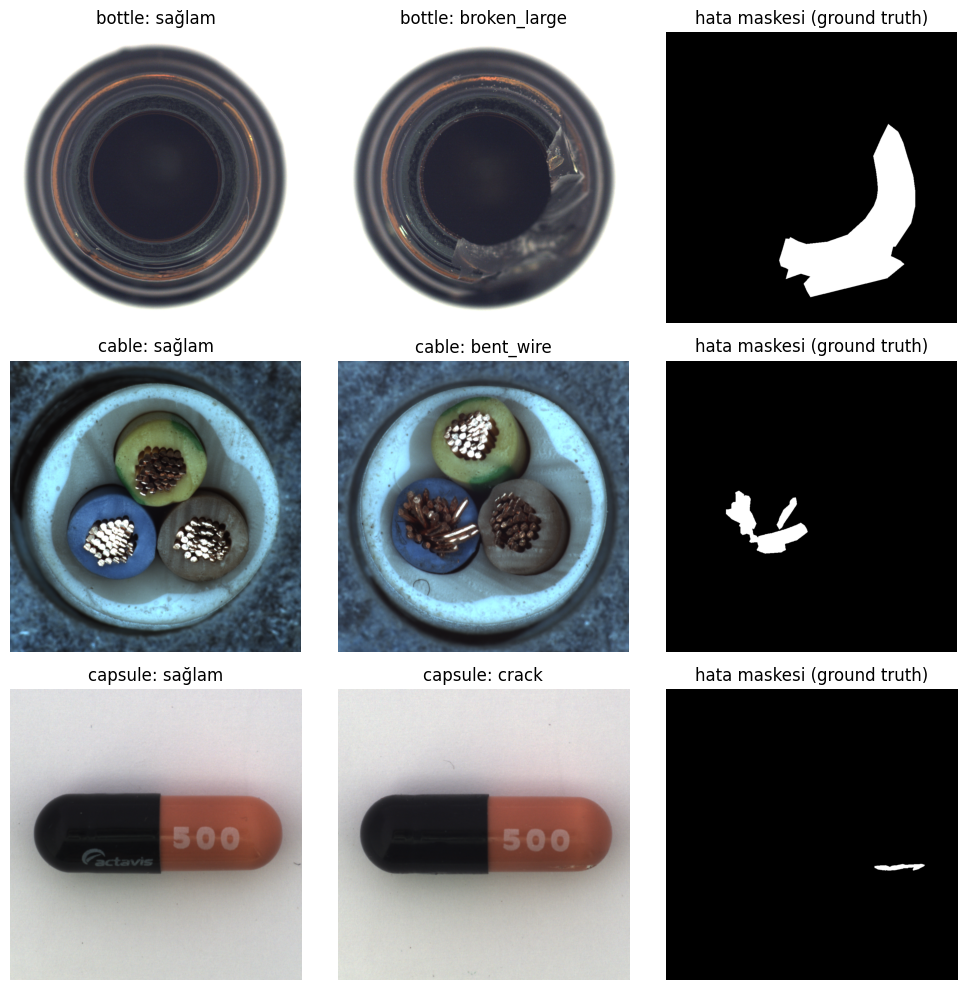

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

FIG_DIR = f'{PROJECT_DIR}/figures'   # README görselleri (kalıcı)
os.makedirs(FIG_DIR, exist_ok=True)

fig, axes = plt.subplots(len(CATEGORIES), 3, figsize=(10, 10))
for i, cat in enumerate(CATEGORIES):
    root = f'{DATASET_ROOT}/{cat}'
    good = sorted(os.listdir(f'{root}/train/good'))[0]
    defect = sorted(d for d in os.listdir(f'{root}/test') if d != 'good')[0]
    bad = sorted(os.listdir(f'{root}/test/{defect}'))[0]
    mask = bad.replace('.png', '_mask.png')

    paths  = [f'{root}/train/good/{good}',
              f'{root}/test/{defect}/{bad}',
              f'{root}/ground_truth/{defect}/{mask}']
    titles = [f'{cat}: sağlam', f'{cat}: {defect}', 'hata maskesi (ground truth)']

    for ax, p, t in zip(axes[i], paths, titles):
        ax.imshow(Image.open(p), cmap='gray')
        ax.set_title(t)
        ax.axis('off')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/dataset_samples.png', dpi=120)
plt.show()

## 3. Eğitim — PatchCore

Her kategori için ayrı bir model eğitilir. PatchCore geri yayılım kullanmaz: önceden eğitilmiş WideResNet50'nin `layer2` + `layer3` özniteliklerinden bir hafıza bankası oluşturur ve coreset ile %10'a küçültür.


In [6]:
import time, shutil
import pandas as pd
from anomalib.data import MVTecAD
from anomalib.models import Patchcore
from anomalib.engine import Engine

CORESET_RATIO = 0.1

def train_category(cat):
    """Bir kategori için PatchCore eğitir, test eder, modeli Drive'a yedekler."""
    datamodule = MVTecAD(root=DATASET_ROOT, category=cat,
                         train_batch_size=32, eval_batch_size=32, num_workers=2)
    model = Patchcore(backbone='wide_resnet50_2', layers=['layer2', 'layer3'],
                      coreset_sampling_ratio=CORESET_RATIO)
    engine = Engine(default_root_dir=RESULTS_ROOT, enable_progress_bar=False)

    t0 = time.time()
    engine.fit(model=model, datamodule=datamodule)
    train_min = (time.time() - t0) / 60

    metrics = engine.test(model=model, datamodule=datamodule)[0]

    # Modeli kalıcı depolamaya yedekle
    ver_dir = os.path.realpath(f'{RESULTS_ROOT}/Patchcore/MVTecAD/{cat}/latest')
    shutil.copy(f'{ver_dir}/weights/lightning/model.ckpt',
                f'{MODELS_DIR}/patchcore_{cat}.ckpt')

    return {'category': cat, 'train_min': round(train_min, 2), 'version_dir': ver_dir, **metrics}

results = []
for cat in CATEGORIES:
    print(f'\n{"="*20} {cat.upper()} {"="*20}')
    results.append(train_category(cat))

df = pd.DataFrame(results)
df.to_csv(f'{PROJECT_DIR}/results_summary.csv', index=False)
df.drop(columns=['version_dir']).round(3)

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention



==================== BOTTLE ====================


model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type           ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor   │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor  │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator      │      0 │ train │     0 │
│ 3 │ model          │ PatchcoreModel │ 24.9 M │ train │     0 │
└───┴────────────────┴────────────────┴────────┴───────┴───────┘

... (12 outputs left out)

Trainable params: 24.9 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 24.9 M                                                                                               
Total estimated model params size (MB): 99.450                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 174                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 174 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.
Selecting Coreset Indices.: 100%|██████████| 22424/22424 [01:18<00:00, 285.71it/s]
INFO:lightning_fabric.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│        image_AUROC        │     0.992820143699646     │
│       image_F1Score       │    0.9767441749572754     │
│        pixel_AUROC        │    0.9900406002998352     │
│       pixel_F1Score       │    0.5150878429412842     │
└───────────────────────────┴───────────────────────────┘

,category,train_min,image_AUROC,image_F1Score,pixel_AUROC,pixel_F1Score
0,bottle,1.45,1.000,0.992,0.986,0.727
1,cable,1.72,0.986,0.967,0.985,0.641
2,capsule,1.68,0.993,0.977,0.990,0.515


## 4. Sonuçlar — Anomali Haritaları

Her satır: orijinal görüntü · gerçek hata maskesi · modelin anomali haritası · tahmin edilen hata bölgesi.

bottle: toplam 83 sonuç görseli | gösterilen: ['good', 'broken_large', 'broken_small', 'contamination']


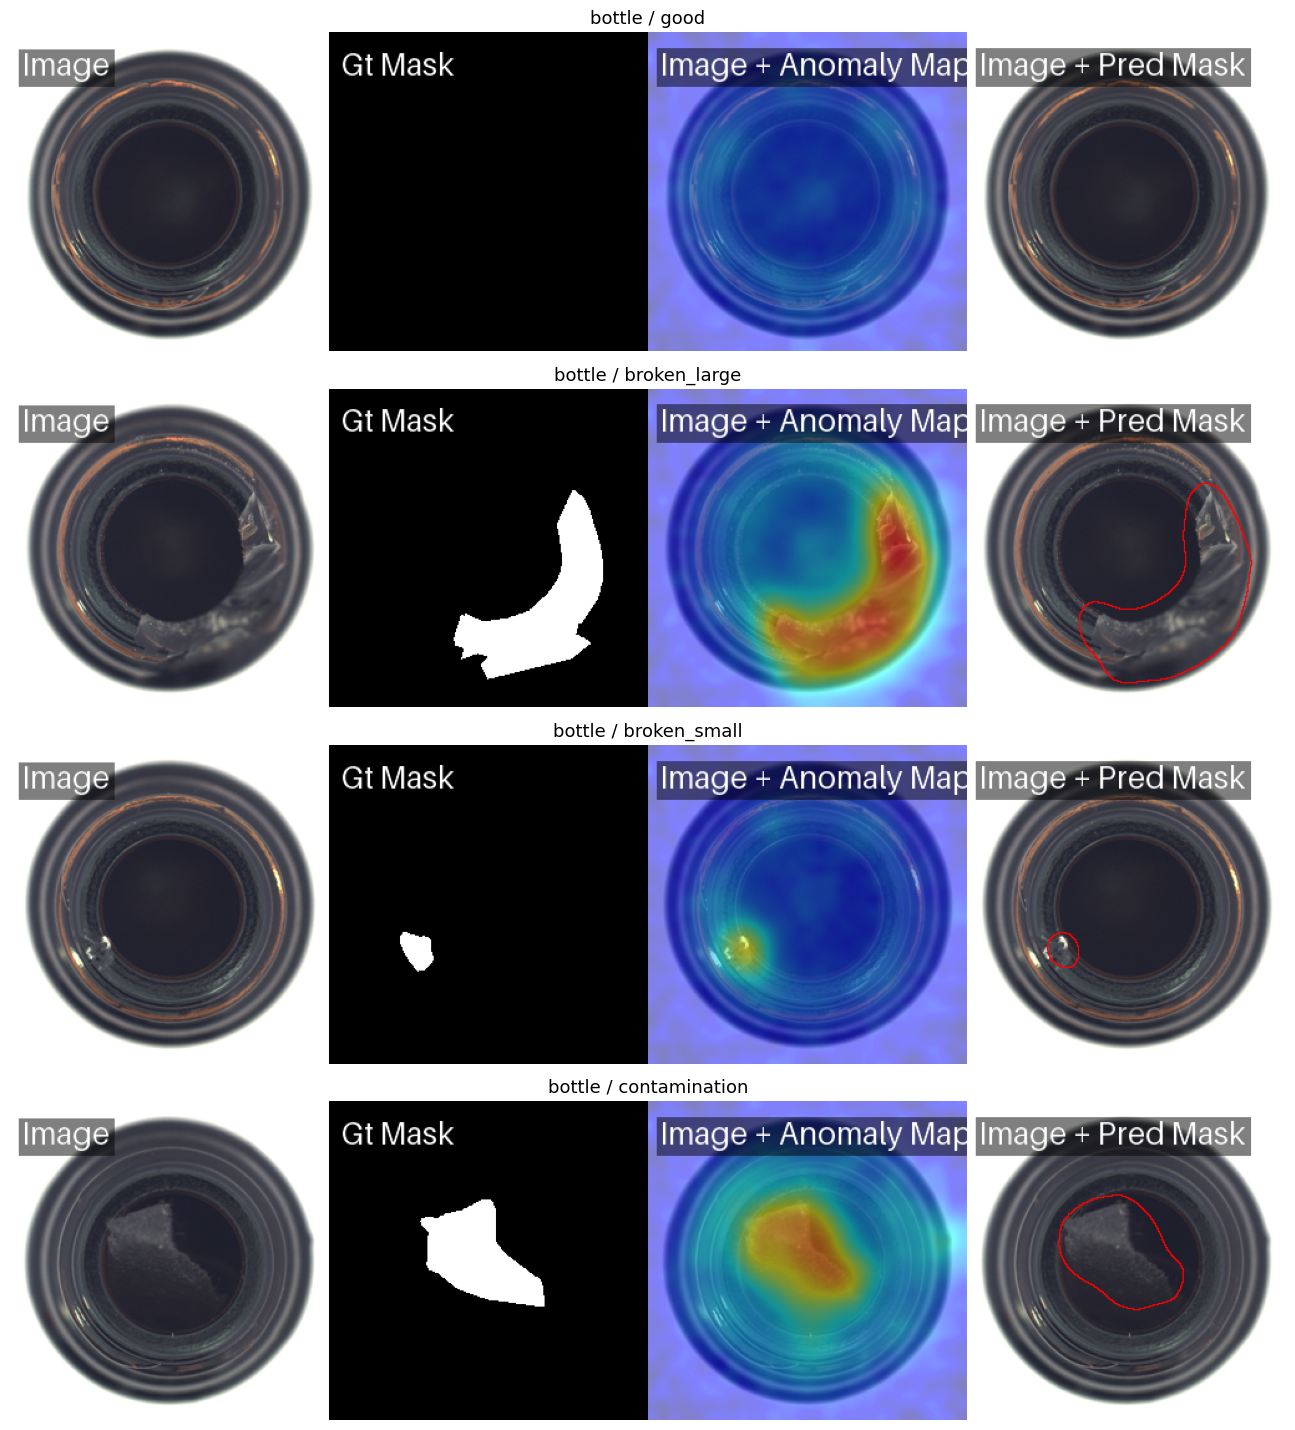

cable: toplam 150 sonuç görseli | gösterilen: ['good', 'bent_wire', 'cable_swap', 'combined']


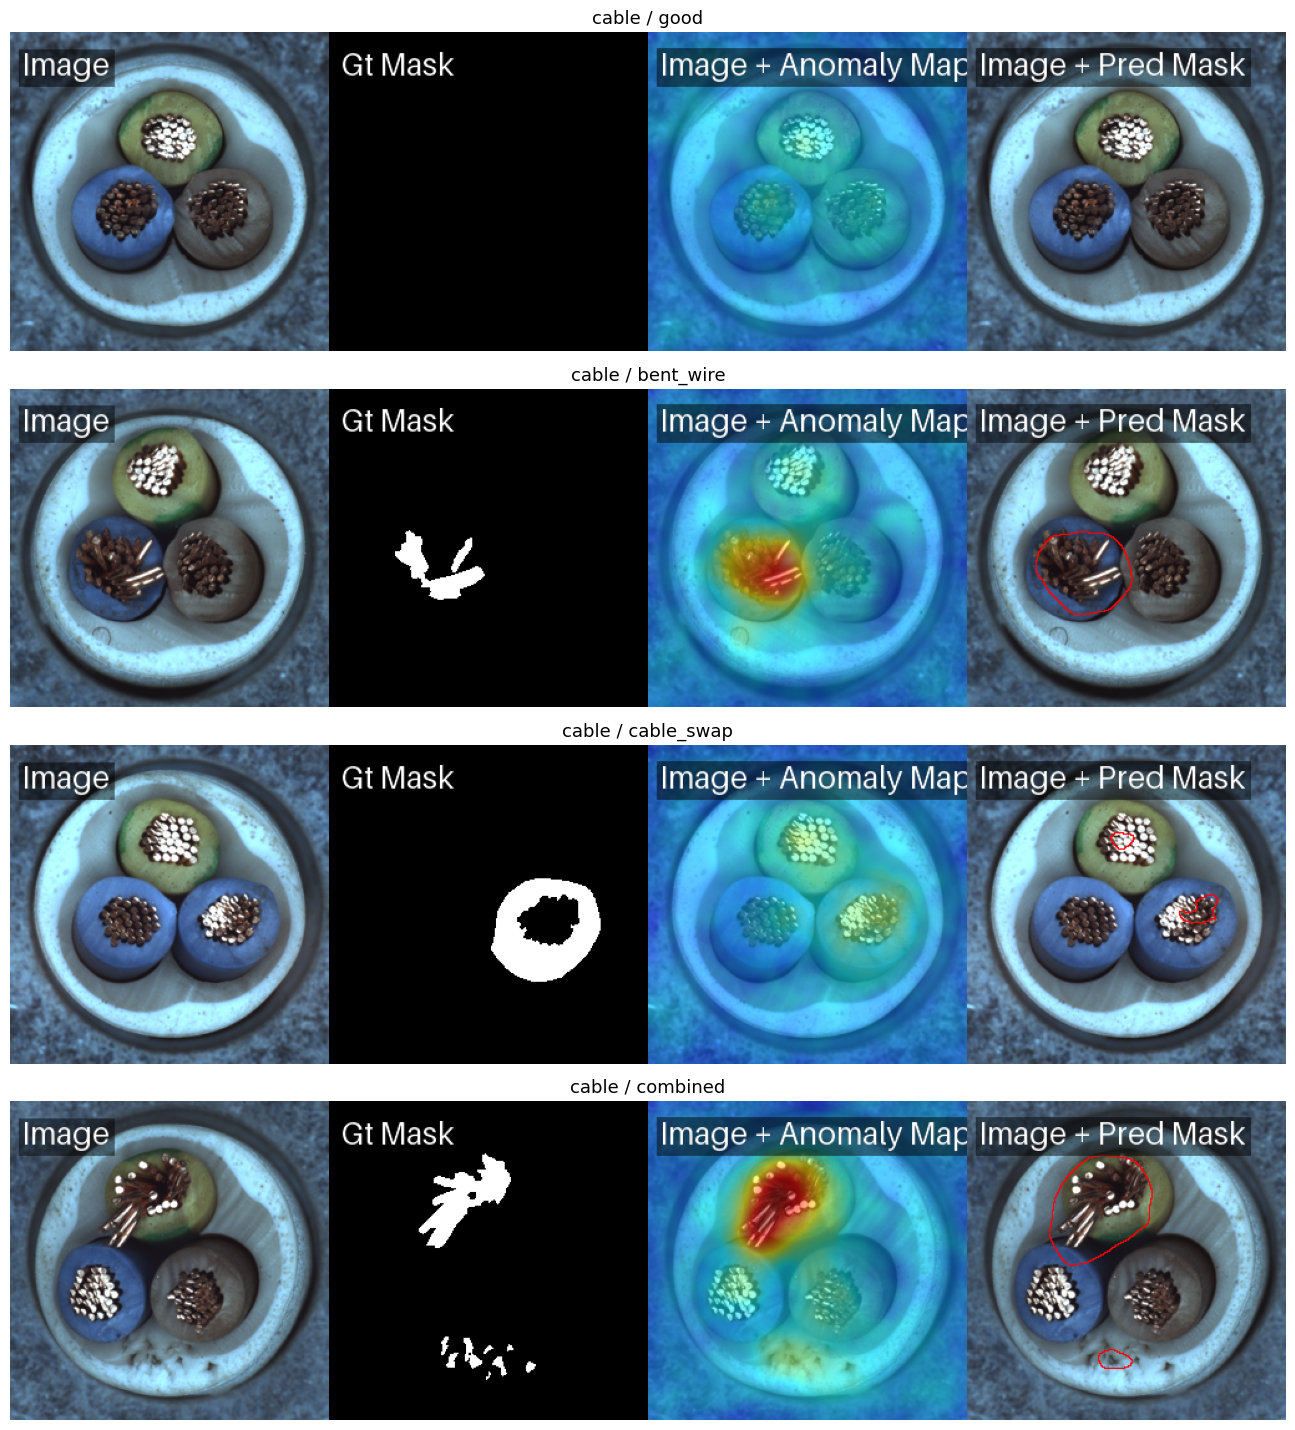

capsule: toplam 132 sonuç görseli | gösterilen: ['good', 'crack', 'faulty_imprint', 'poke']


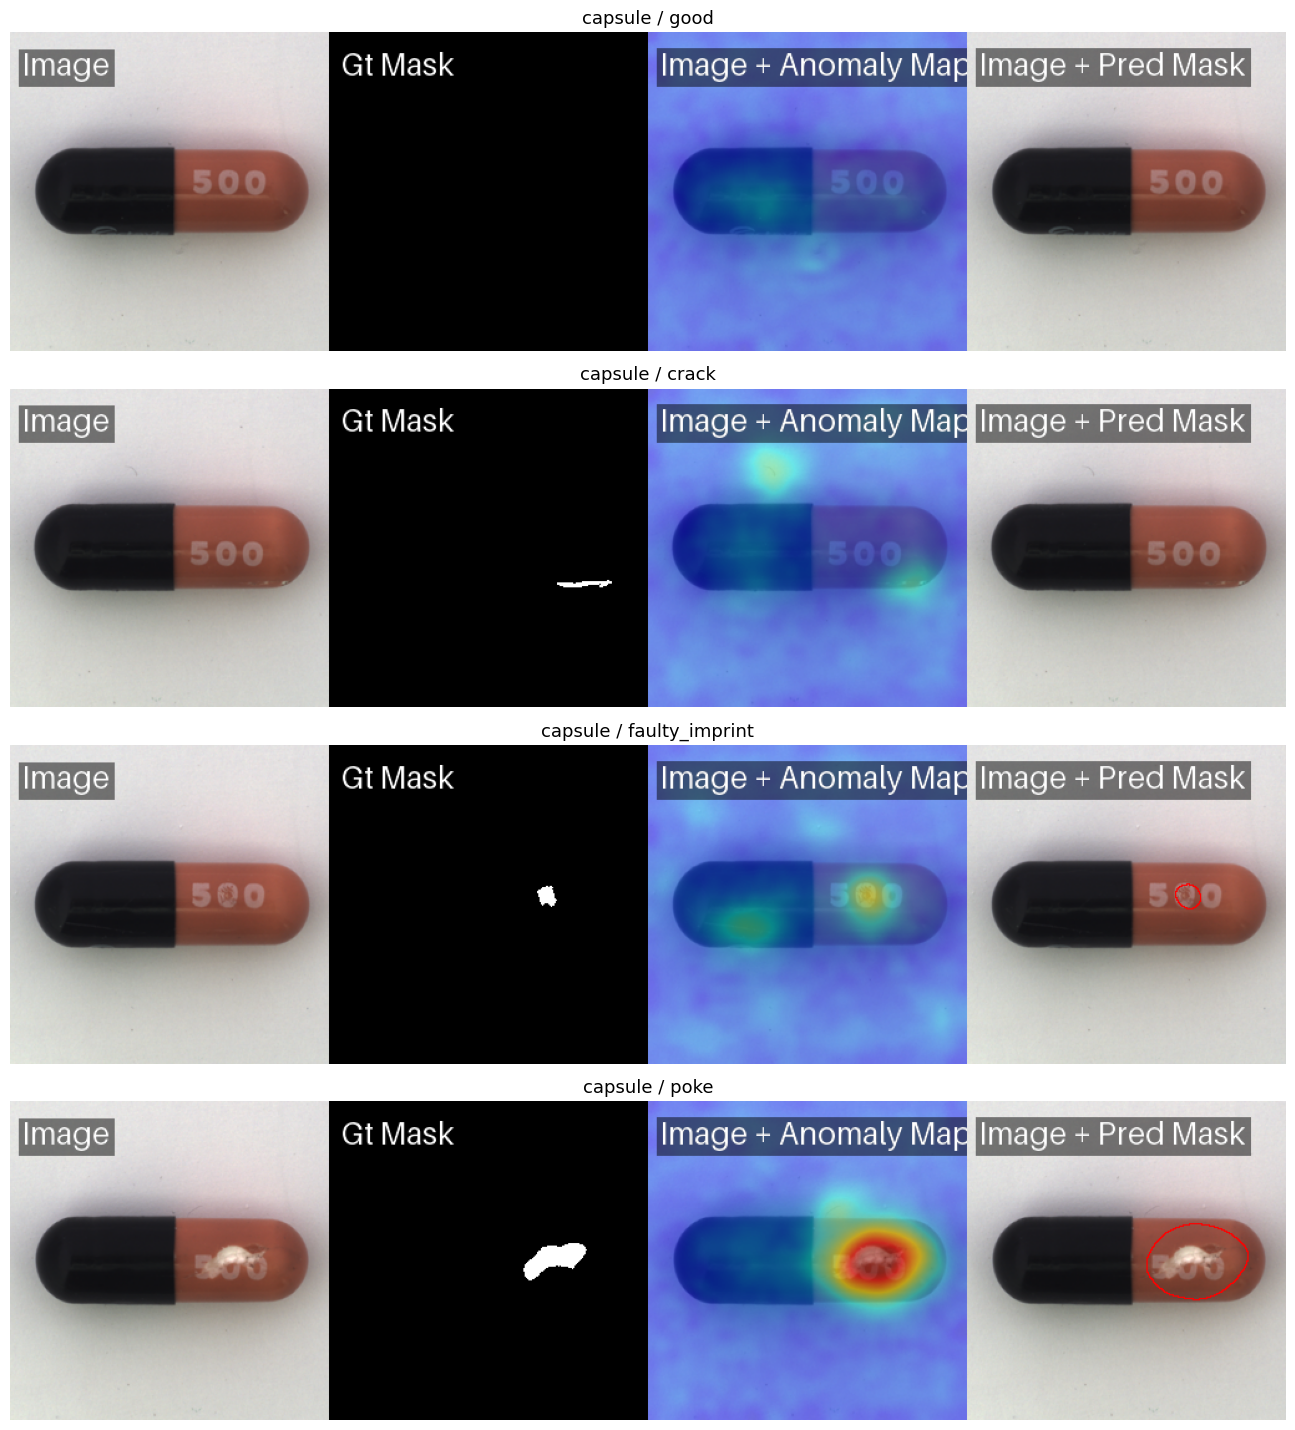

In [7]:
import glob
import numpy as np

for r in results:
    cat = r['category']
    imgs = sorted(glob.glob(f"{r['version_dir']}/images/**/*.png", recursive=True))

    # Her klasörden (hata türünden) ilk görseli seç: 'good' + en fazla 3 hata türü
    picks = {}
    for p in imgs:
        defect = os.path.basename(os.path.dirname(p))
        picks.setdefault(defect, p)
    order = (['good'] if 'good' in picks else []) + [d for d in picks if d != 'good'][:3]

    print(f'{cat}: toplam {len(imgs)} sonuç görseli | gösterilen: {order}')
    fig, axes = plt.subplots(len(order), 1, figsize=(14, 3.6 * len(order)))
    for ax, d in zip(np.atleast_1d(axes), order):
        ax.imshow(Image.open(picks[d]))
        ax.set_title(f'{cat} / {d}', fontsize=13)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/heatmaps_{cat}.png', dpi=110)
    plt.show()

## 5. Eşik Analizi

Model her görüntüye bir **anomali skoru** verir. Skor eşiğin üstündeyse görüntü "hatalı" sayılır. Eşiğin yeri, yakalanan hata ile yanlış alarm arasındaki dengeyi belirler.


INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning_fabric.utilities.rank_zero:Restoring states from the checkpoint path at /content/drive/MyDrive/edge-anomaly-detection-rpi5/models/patchcore_cable.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:Loaded model weights from the checkpoint at /content/drive/MyDrive/edge-anomaly-detection-rpi5/models/patchcore_cable.ckpt
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespe

150 görüntü | sağlam: 58 | hatalı: 92


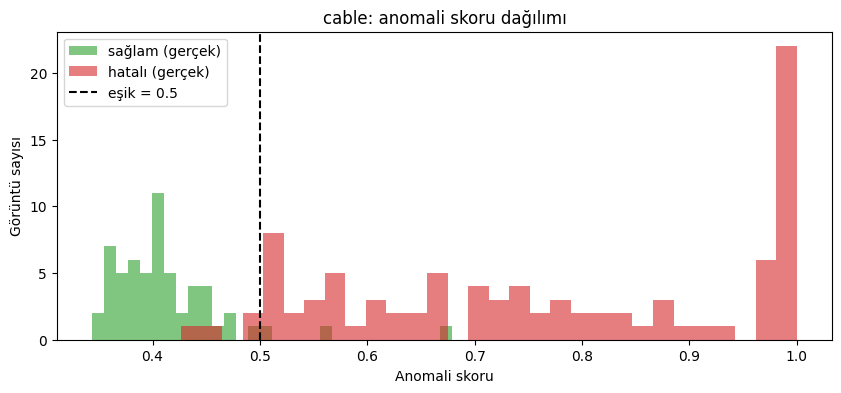

In [8]:
cat = 'cable'
datamodule = MVTecAD(root=DATASET_ROOT, category=cat, eval_batch_size=32, num_workers=2)
model = Patchcore(backbone='wide_resnet50_2', layers=['layer2', 'layer3'])
engine = Engine(default_root_dir=RESULTS_ROOT, enable_progress_bar=False)

# Eğitilmiş modeli Drive'daki yedekten yükleyip her test görüntüsü için tahmin al
preds = engine.predict(model=model, datamodule=datamodule,
                       ckpt_path=f'{MODELS_DIR}/patchcore_{cat}.ckpt')

scores = np.concatenate([b.pred_score.cpu().numpy().ravel() for b in preds])
labels = np.concatenate([b.gt_label.cpu().numpy().ravel() for b in preds]).astype(int)
print(f'{len(scores)} görüntü | sağlam: {(labels==0).sum()} | hatalı: {(labels==1).sum()}')

# Skor dağılımı
plt.figure(figsize=(10, 4))
plt.hist(scores[labels == 0], bins=30, alpha=0.6, color='tab:green', label='sağlam (gerçek)')
plt.hist(scores[labels == 1], bins=30, alpha=0.6, color='tab:red',   label='hatalı (gerçek)')
plt.axvline(0.5, color='black', linestyle='--', label='eşik = 0.5')
plt.xlabel('Anomali skoru'); plt.ylabel('Görüntü sayısı')
plt.title(f'{cat}: anomali skoru dağılımı')
plt.legend()
plt.savefig(f'{FIG_DIR}/score_hist_{cat}.png', dpi=120)
plt.show()

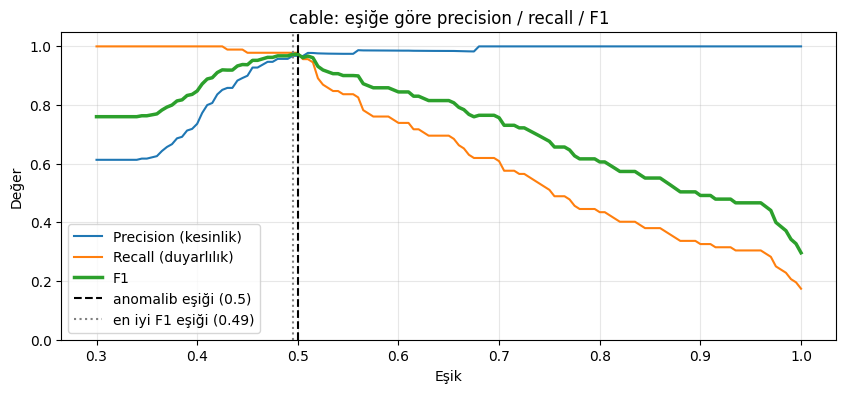

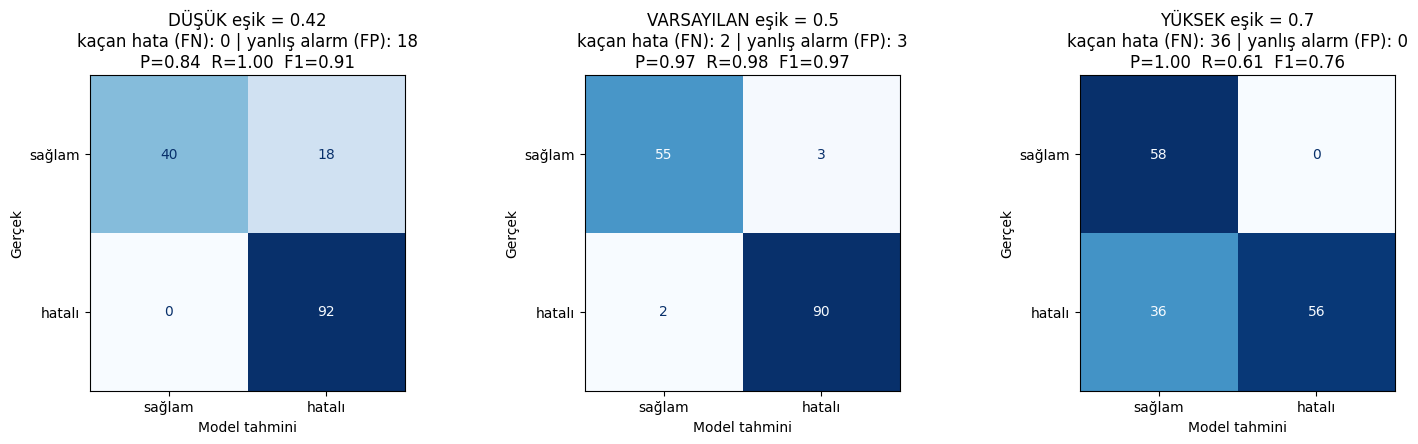

In [9]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# --- 1) Eşik taraması: her eşik için P, R, F1 ---
ths = np.linspace(0.30, 1.00, 141)
P, R, F = [], [], []
for t in ths:
    pred = (scores >= t).astype(int)
    P.append(precision_score(labels, pred, zero_division=0))
    R.append(recall_score(labels, pred, zero_division=0))
    F.append(f1_score(labels, pred, zero_division=0))
best_t = ths[int(np.argmax(F))]

plt.figure(figsize=(10, 4))
plt.plot(ths, P, label='Precision (kesinlik)')
plt.plot(ths, R, label='Recall (duyarlılık)')
plt.plot(ths, F, label='F1', linewidth=2.5)
plt.axvline(0.5, color='black', linestyle='--', label='anomalib eşiği (0.5)')
plt.axvline(best_t, color='gray', linestyle=':', label=f'en iyi F1 eşiği ({best_t:.2f})')
plt.xlabel('Eşik'); plt.ylabel('Değer'); plt.ylim(0, 1.05)
plt.title(f'{cat}: eşiğe göre precision / recall / F1')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(f'{FIG_DIR}/threshold_sweep_{cat}.png', dpi=120)
plt.show()

# --- 2) Üç farklı eşikte karışıklık matrisi ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, t, name in zip(axes, [0.42, 0.50, 0.70], ['DÜŞÜK eşik', 'VARSAYILAN eşik', 'YÜKSEK eşik']):
    pred = (scores >= t).astype(int)
    cm = confusion_matrix(labels, pred)
    ConfusionMatrixDisplay(cm, display_labels=['sağlam', 'hatalı']).plot(ax=ax, colorbar=False, cmap='Blues')
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f'{name} = {t}\nkaçan hata (FN): {fn} | yanlış alarm (FP): {fp}\n'
                 f'P={precision_score(labels, pred):.2f}  R={recall_score(labels, pred):.2f}  F1={f1_score(labels, pred):.2f}')
    ax.set_xlabel('Model tahmini'); ax.set_ylabel('Gerçek')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/confusion_matrices_{cat}.png', dpi=120)
plt.show()

## 6. Dışa Aktarma (Edge Deployment)

Eğitilen modeller **OpenVINO IR** ve **ONNX** formatlarına dönüştürülür. Bu formatlar PyTorch gerektirmeden, yalnızca hafif bir çıkarım motoruyla Raspberry Pi 5 üzerinde çalışır.


In [10]:
from anomalib.deploy import ExportType

EXPORT_LOCAL = '/content/exports'                 # geçici
EXPORT_DRIVE = f'{PROJECT_DIR}/exports'           # kalıcı

for cat in CATEGORIES:
    ckpt = f'{MODELS_DIR}/patchcore_{cat}.ckpt'
    for et in [ExportType.OPENVINO, ExportType.ONNX]:
        model = Patchcore(backbone='wide_resnet50_2', layers=['layer2', 'layer3'])
        engine = Engine(default_root_dir=RESULTS_ROOT, enable_progress_bar=False)
        out = engine.export(model=model, export_type=et,
                            export_root=f'{EXPORT_LOCAL}/{cat}', ckpt_path=ckpt)
        print(f'✅ {cat:8s} | {et.value:9s} → {out}')

shutil.copytree(EXPORT_LOCAL, EXPORT_DRIVE, dirs_exist_ok=True)
print('\n💾 Drive\'a kopyalandı. Dosya boyutları:')
!find {EXPORT_LOCAL} -type f -exec du -h {} \; | sort -k2

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
W1125 17:13:55.327000 476 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 14 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `Patchcore([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Patchcore([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
✅ bottle   | openvino  → /content/exports/bottle/weights/openvino/model.xml
✅ bottle   | openvino  → /content/exports/bottle/weights/openvino/model.xml


INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
W1125 17:14:20.905000 476 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 14 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `Patchcore([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Patchcore([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...


... (14 outputs left out)

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
W1125 17:15:40.564000 476 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 14 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `Patchcore([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Patchcore([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
✅ capsule  | onnx      → /content/exports/capsule/weights/onnx/model.onnx

💾 Drive'a kopyalandı. Dosya boyutları:
find: ‘{EXPORT_LOCAL}’: No such file or directory


In [11]:
print(f'{"Boyut":>9} | Dosya')
print('-' * 55)
for root, _, files in sorted(os.walk(EXPORT_LOCAL)):
    for f in sorted(files):
        p = os.path.join(root, f)
        print(f'{os.path.getsize(p)/1e6:7.1f} MB | {os.path.relpath(p, EXPORT_LOCAL)}')

    Boyut | Dosya
-------------------------------------------------------
    0.3 MB | bottle/weights/onnx/model.onnx
  230.9 MB | bottle/weights/onnx/model.onnx.data
  230.9 MB | bottle/weights/openvino/model.bin
    0.2 MB | bottle/weights/openvino/model.xml
    0.3 MB | cable/weights/onnx/model.onnx
  240.3 MB | cable/weights/onnx/model.onnx.data
  240.4 MB | cable/weights/openvino/model.bin
    0.2 MB | cable/weights/openvino/model.xml
    0.3 MB | capsule/weights/onnx/model.onnx
  237.2 MB | capsule/weights/onnx/model.onnx.data
  237.2 MB | capsule/weights/openvino/model.bin
    0.2 MB | capsule/weights/openvino/model.xml
